# COVID-19 in Texas Counties: SQL Window Functions in Practice

**Author:** JaDarrien Tatum · M.S. Data Science student, Tarleton State University

The New York Times publishes **cumulative** COVID-19 case and death counts for every U.S. county by day. Cumulative totals are hard to act on, so this project uses SQL window functions in **DuckDB** to turn them into the numbers decision-makers actually use:

1. **Daily new cases** from cumulative totals (`LAG`), with downward reporting corrections handled.
2. **7-day rolling averages** (`AVG(...) OVER (... ROWS BETWEEN 6 PRECEDING AND CURRENT ROW)`).
3. **Cases per 100,000 residents** using a population lookup table (`JOIN`).
4. **Each county's worst week** (`ROW_NUMBER`) and month-by-month comparisons (`DATE_TRUNC`, conditional aggregation).

Focus: the ten most populous Texas counties, with a closer look at Dallas–Fort Worth (Dallas, Tarrant, Collin, Denton).

## Setup
DuckDB reads the three yearly CSV files straight from the NYT GitHub repository over HTTPS and keeps only Texas rows.

In [ ]:
import duckdb, pandas as pd, matplotlib.pyplot as plt

con = duckdb.connect()
con.execute("INSTALL httpfs; LOAD httpfs;")
BASE = "https://raw.githubusercontent.com/nytimes/covid-19-data/master/"
files = [BASE + f"us-counties-{y}.csv" for y in (2020, 2021, 2022)]

con.execute(f"""
CREATE OR REPLACE TABLE tx AS
SELECT CAST(date AS DATE) AS date, county,
       CAST(cases AS BIGINT) AS cases, CAST(deaths AS BIGINT) AS deaths
FROM read_csv_auto({files}, union_by_name = true)
WHERE state = 'Texas' AND county <> 'Unknown'
""")

def q(sql):
    """Run a SQL query and return the result as a pandas DataFrame."""
    return con.execute(sql).fetchdf()

q("SELECT COUNT(*) AS rows, COUNT(DISTINCT county) AS counties, MIN(date) AS first_day, MAX(date) AS last_day FROM tx")

,rows,counties,first_day,last_day
0,252446,255,2020-02-12,2022-12-31


## Population lookup (2020 Census)
A `VALUES` table holds the 2020 Census population of the ten largest Texas counties so counties of different sizes can be compared fairly per 100,000 residents.

In [ ]:
con.execute("""
CREATE OR REPLACE TABLE pop AS
SELECT * FROM (VALUES
  ('Harris',    4731145, 'Houston'),
  ('Dallas',    2613539, 'DFW'),
  ('Tarrant',   2110640, 'DFW'),
  ('Bexar',     2009324, 'San Antonio'),
  ('Travis',    1290188, 'Austin'),
  ('Collin',    1064465, 'DFW'),
  ('Denton',     906422, 'DFW'),
  ('Hidalgo',    870781, 'Rio Grande Valley'),
  ('El Paso',    865657, 'El Paso'),
  ('Fort Bend',  822779, 'Houston')
) AS t(county, population, metro)
""")
q("SELECT * FROM pop ORDER BY population DESC")

,county,population,metro
0,Harris,4731145,Houston
1,Dallas,2613539,DFW
2,Tarrant,2110640,DFW
3,Bexar,2009324,San Antonio
4,Travis,1290188,Austin
5,Collin,1064465,DFW
6,Denton,906422,DFW
7,Hidalgo,870781,Rio Grande Valley
8,El Paso,865657,El Paso
9,Fort Bend,822779,Houston


## 1. Daily new cases from cumulative totals
`LAG` looks back one row within each county. Counties occasionally revise their totals downward, which would create negative "new" cases, so those days are floored at zero with `GREATEST`.

In [ ]:
con.execute("""
CREATE OR REPLACE TABLE daily AS
SELECT t.date, t.county, p.metro, p.population,
       GREATEST(t.cases  - LAG(t.cases,  1, 0) OVER w, 0) AS new_cases,
       GREATEST(t.deaths - LAG(t.deaths, 1, 0) OVER w, 0) AS new_deaths
FROM tx t
JOIN pop p USING (county)
WINDOW w AS (PARTITION BY t.county ORDER BY t.date)
""")
q("SELECT * FROM daily WHERE county = 'Dallas' ORDER BY date LIMIT 8")

,date,county,metro,population,new_cases,new_deaths
0,2020-03-10,Dallas,DFW,2613539,2,0
1,2020-03-11,Dallas,DFW,2613539,1,0
2,2020-03-12,Dallas,DFW,2613539,5,0
3,2020-03-13,Dallas,DFW,2613539,1,0
4,2020-03-14,Dallas,DFW,2613539,2,0
5,2020-03-15,Dallas,DFW,2613539,3,0
6,2020-03-16,Dallas,DFW,2613539,0,0
7,2020-03-17,Dallas,DFW,2613539,9,0


## 2. 7-day rolling average per 100,000 residents

In [ ]:
con.execute("""
CREATE OR REPLACE TABLE rolling AS
SELECT date, county, metro,
       AVG(new_cases) OVER w                         AS cases_7d,
       AVG(new_cases) OVER w * 100000.0 / population AS cases_7d_per_100k
FROM daily
WINDOW w AS (PARTITION BY county ORDER BY date ROWS BETWEEN 6 PRECEDING AND CURRENT ROW)
""")
q("SELECT * FROM rolling WHERE county = 'Tarrant' AND date BETWEEN '2022-01-08' AND '2022-01-14' ORDER BY date")

,date,county,metro,cases_7d,cases_7d_per_100k
0,2022-01-08,Tarrant,DFW,4185.857143,198.321701
1,2022-01-09,Tarrant,DFW,4621.857143,218.978942
2,2022-01-10,Tarrant,DFW,3809.000000,180.466588
3,2022-01-11,Tarrant,DFW,3780.857143,179.133208
4,2022-01-12,Tarrant,DFW,4245.571429,201.150903
5,2022-01-13,Tarrant,DFW,4680.428571,221.753997
6,2022-01-14,Tarrant,DFW,6060.857143,287.157315


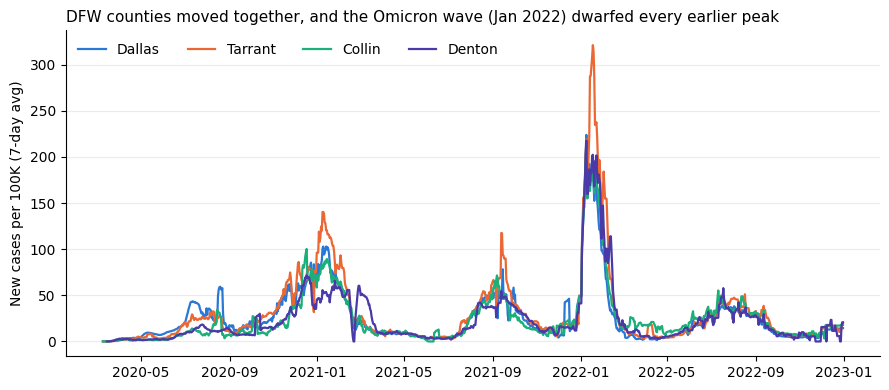

In [ ]:
dfw = q("SELECT date, county, cases_7d_per_100k FROM rolling WHERE metro = 'DFW' ORDER BY date")
colors = {"Dallas": "#2a78d6", "Tarrant": "#eb6834", "Collin": "#1baf7a", "Denton": "#4a3aa7"}
fig, ax = plt.subplots(figsize=(9, 4))
for c, col in colors.items():
    s = dfw[dfw.county == c]
    ax.plot(s.date, s.cases_7d_per_100k, color=col, lw=1.6, label=c)
ax.set_ylabel("New cases per 100K (7-day avg)")
ax.set_title("DFW counties moved together, and the Omicron wave (Jan 2022) dwarfed every earlier peak", loc="left", fontsize=11)
ax.legend(frameon=False, ncol=4, loc="upper left")
for s in ["top", "right"]: ax.spines[s].set_visible(False)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout(); plt.show()

## 3. Each county's worst week (`ROW_NUMBER`)

In [ ]:
q("""
WITH ranked AS (
  SELECT county, metro, date, cases_7d, cases_7d_per_100k,
         ROW_NUMBER() OVER (PARTITION BY county ORDER BY cases_7d_per_100k DESC) AS rn
  FROM rolling
)
SELECT county, metro, date AS peak_date,
       ROUND(cases_7d)          AS peak_daily_avg,
       ROUND(cases_7d_per_100k) AS peak_per_100k
FROM ranked
WHERE rn = 1
ORDER BY peak_per_100k DESC
""")

,county,metro,peak_date,peak_daily_avg,peak_per_100k
0,Harris,Houston,2022-01-17,19442.0,411.0
1,Bexar,San Antonio,2022-01-18,7476.0,372.0
2,Fort Bend,Houston,2022-01-09,2885.0,351.0
3,Hidalgo,Rio Grande Valley,2022-01-18,2839.0,326.0
4,Tarrant,DFW,2022-01-18,6775.0,321.0
5,Travis,Austin,2022-01-17,3451.0,267.0
6,El Paso,El Paso,2022-01-25,2056.0,238.0
7,Dallas,DFW,2022-01-09,5849.0,224.0
8,Denton,DFW,2022-01-09,1973.0,218.0
9,Collin,DFW,2022-01-09,2259.0,212.0


## 4. The biggest months (conditional aggregation pivot)
One query pivots new cases into a column per metro area with `SUM(CASE ...)`, the portable way to pivot in SQL.

In [ ]:
q("""
SELECT DATE_TRUNC('month', date)                                       AS month,
       SUM(CASE WHEN metro = 'DFW'         THEN new_cases ELSE 0 END)  AS dfw,
       SUM(CASE WHEN metro = 'Houston'     THEN new_cases ELSE 0 END)  AS houston,
       SUM(CASE WHEN metro = 'San Antonio' THEN new_cases ELSE 0 END)  AS san_antonio,
       SUM(CASE WHEN metro = 'Austin'      THEN new_cases ELSE 0 END)  AS austin
FROM daily
GROUP BY month
ORDER BY dfw DESC
LIMIT 6
""")

,month,dfw,houston,san_antonio,austin
0,2022-01-01,360196.0,356508.0,168021.0,75694.0
1,2021-01-01,170759.0,93595.0,57469.0,18136.0
2,2020-12-01,141235.0,60219.0,34511.0,12218.0
3,2021-09-01,105976.0,69856.0,27184.0,11939.0
4,2021-08-01,85898.0,84357.0,44723.0,13736.0
5,2020-11-01,84070.0,33110.0,15301.0,6234.0


## 5. Deaths per 100 reported cases, by year
A rough severity indicator for each period. It also reflects how much testing was being done, so it is compared across years rather than read as a true fatality rate.

In [ ]:
q("""
SELECT county,
       ROUND(100.0 * SUM(CASE WHEN year(date) = 2020 THEN new_deaths END)
                   / NULLIF(SUM(CASE WHEN year(date) = 2020 THEN new_cases END), 0), 2) AS deaths_per_100_cases_2020,
       ROUND(100.0 * SUM(CASE WHEN year(date) = 2021 THEN new_deaths END)
                   / NULLIF(SUM(CASE WHEN year(date) = 2021 THEN new_cases END), 0), 2) AS deaths_per_100_cases_2021,
       ROUND(100.0 * SUM(CASE WHEN year(date) = 2022 THEN new_deaths END)
                   / NULLIF(SUM(CASE WHEN year(date) = 2022 THEN new_cases END), 0), 2) AS deaths_per_100_cases_2022
FROM daily
GROUP BY county
ORDER BY deaths_per_100_cases_2021 DESC
""")

,county,deaths_per_100_cases_2020,deaths_per_100_cases_2021,deaths_per_100_cases_2022
0,El Paso,1.69,2.14,0.71
1,Hidalgo,4.23,1.90,0.37
2,Bexar,1.49,1.62,0.31
3,Dallas,1.03,1.55,0.48
4,Harris,1.43,1.54,0.29
5,Tarrant,1.00,1.48,0.42
6,Travis,1.09,1.15,0.21
7,Denton,0.90,0.95,0.33
8,Collin,0.77,0.91,0.31
9,Fort Bend,1.07,0.86,0.21


## Findings

- **Coverage:** 252,446 county-days across 255 Texas counties, from Feb 12, 2020 through Dec 31, 2022.
- **Omicron was the peak everywhere.** All ten of the largest counties hit their worst 7-day average between Jan 9 and Jan 25, 2022.
- **Peak intensity varied widely.** Harris peaked at 411 new cases per 100,000 residents per day. In DFW, Tarrant peaked at 321, about 43% above Dallas (224), Denton (218) and Collin (212).
- **One month dwarfed the rest.** DFW recorded 360,196 new cases in January 2022, more than double its next-worst month (170,759 in January 2021).
- **Severity fell sharply in 2022.** Deaths per 100 reported cases dropped sharply, for example El Paso from 2.14 in 2021 to 0.71 in 2022 and Hidalgo from 1.90 to 0.37, consistent with vaccination and a milder variant (with the caveat that testing levels changed too).